# 04 · Model 2 — Decision Tree (CART)

**Idea:** ask a series of **yes/no questions** about the features, like a flow chart:
*"Is the s11 drift > 0.2?" → yes → "Is the cycle > 150?" → …* and at the end predict the **average RUL** of that group.

* Built with the **CART** algorithm: at every step it picks the feature + threshold that best splits the data.
* It can learn **non-linear** patterns ("flat, then drop") — which linear models cannot.
* Needs **no scaling** (it only compares a feature with a threshold).
* Risk: a deep tree **overfits**. We control it with **pruning**:
  * *pre-pruning:* `max_depth`, `min_samples_leaf` (stop growing early)
  * *post-pruning:* `ccp_alpha` (cost-complexity pruning — cut weak branches after growing)


> 💡 Cells marked with **⋯** are hidden because they only contain plotting or helper code. Click them to expand.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.tree import DecisionTreeRegressor, plot_tree
from utils import evaluate, plot_validation, plot_test, stage_table, savefig, COLORS, RUL_CAP, SEED

NAME = "Decision Tree"

## 1. Load the features (made in notebook 02)

In [2]:
# Feature tables made in notebook 02
train = pd.read_csv("../data/processed/train_features.csv")   # 100 training engines, every cycle
test = pd.read_csv("../data/processed/test_features.csv")     # 100 test engines, last cycle only
FEATURES = open("../data/processed/feature_list.txt").read().split()   # the 71 feature names

# Notebook 02 put each training engine in "train" (80 engines) or "val" (20 engines)
tr = train[train["split"] == "train"]
val = train[train["split"] == "val"]

X_train, y_train = tr[FEATURES], tr["RUL"]
X_val, y_val = val[FEATURES], val["RUL"]
groups = tr["unit"]   # engine ID of each row -> cross-validation keeps one engine in one fold
print(f"Training engines: {tr['unit'].nunique()} | Validation engines: {val['unit'].nunique()} | Features: {len(FEATURES)}")

Training engines: 80 | Validation engines: 20 | Features: 71


## 2. Train and tune the model (hyper-parameter tuning)
We try a few settings with **GridSearchCV** and keep the best one.

* **3-fold cross-validation** on the 80 training engines. We use `GroupKFold`, a k-fold where all rows of one engine
  stay in the **same fold** → no data leakage between folds.
* Score = **RMSE** (lower is better).
* The 20 validation engines are **not** used here — only afterwards, to compare models fairly.

In [3]:
base_model = DecisionTreeRegressor(random_state=SEED)
param_grid = {"max_depth": [5, 8, 12, None],          # pre-pruning: how deep the tree can grow
              "min_samples_leaf": [1, 20, 50],        # pre-pruning: minimum rows in a leaf
              "ccp_alpha": [0.0, 1.0, 10.0]}          # post-pruning: cost-complexity pruning

search = GridSearchCV(base_model, param_grid, cv=GroupKFold(n_splits=3),
                      scoring="neg_root_mean_squared_error", n_jobs=-1)
search.fit(X_train, y_train, groups=groups)
model = search.best_estimator_
print("Best settings:", search.best_params_)
print("Cross-validation RMSE of best settings:", round(-search.best_score_, 2))

Best settings: {'ccp_alpha': 0.0, 'max_depth': 12, 'min_samples_leaf': 50}
Cross-validation RMSE of best settings: 13.92


## 3. Results on the validation engines
* **MAE** — average error in cycles
* **RMSE** — √MSE, typical error in cycles (big mistakes count more)
* **R²** — 1 − RSS/TSS: how much of the variation is explained (1 = perfect, 0 = as good as the average)

In [4]:
val_pred = np.clip(model.predict(X_val), 0, RUL_CAP)     # RUL can't be below 0 or above the cap
pd.DataFrame([evaluate(y_val, val_pred)], index=[NAME + " (validation)"])

,RMSE,MAE,R2
Decision Tree (validation),14.13,9.18,0.885


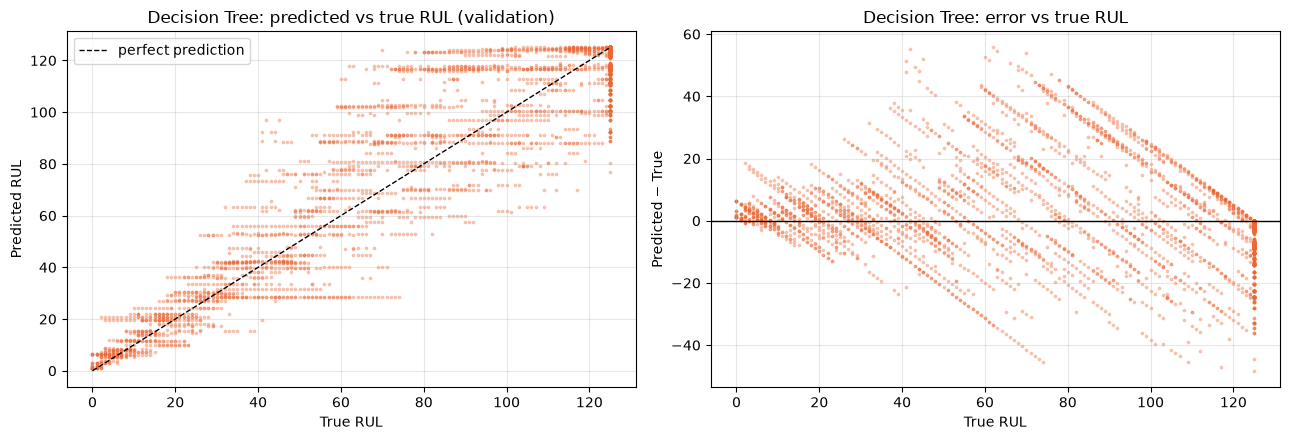

In [5]:
plot_validation(NAME, y_val, val_pred, "04_validation")

**How to read:** left — points on the dashed line are perfect predictions. Right — points above 0 mean the model
predicted **too much** life left (dangerous), below 0 means **too little** (safe but wasteful).

## 4. Which features matter?
Feature importance = how much each feature reduced the error (MSE) in the tree's splits.

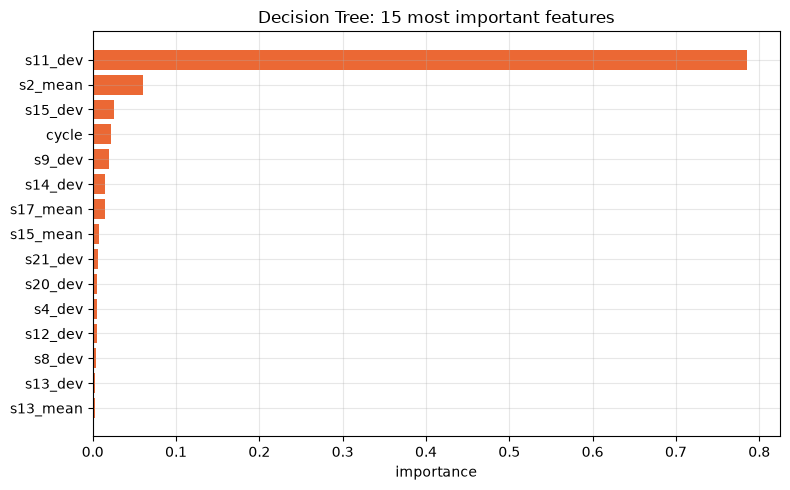

,importance %
dev,88.0
mean,9.6
cycle,2.2
std,0.2
raw sensor,0.0
slope,0.0


In [6]:
imp = pd.Series(model.feature_importances_, index=FEATURES, dtype=float)
top = imp.nlargest(15)
plt.figure(figsize=(8, 5))
plt.barh(top.index[::-1], top.values[::-1], color=COLORS[NAME])
plt.title(f"{NAME}: 15 most important features"); plt.xlabel("importance")
savefig("04_feature_importance")

# Which TYPE of feature matters most? (sum of importances per type)
ftype = lambda f: f.split("_")[1] if "_" in f else ("cycle" if f == "cycle" else "raw sensor")
(imp.groupby(ftype).sum().sort_values(ascending=False) * 100).round(1).to_frame("importance %")

### How the tree decides (top of the tree)
Each box is a **question** about one feature (e.g. "is `s11_dev` ≤ 0.2?"). Going down the tree we end in a **leaf**,
and the prediction is the **average RUL** of the training rows in that leaf.
For regression the tree picks the split that reduces the **MSE** the most (Gini and Entropy are the same idea, used for classification).

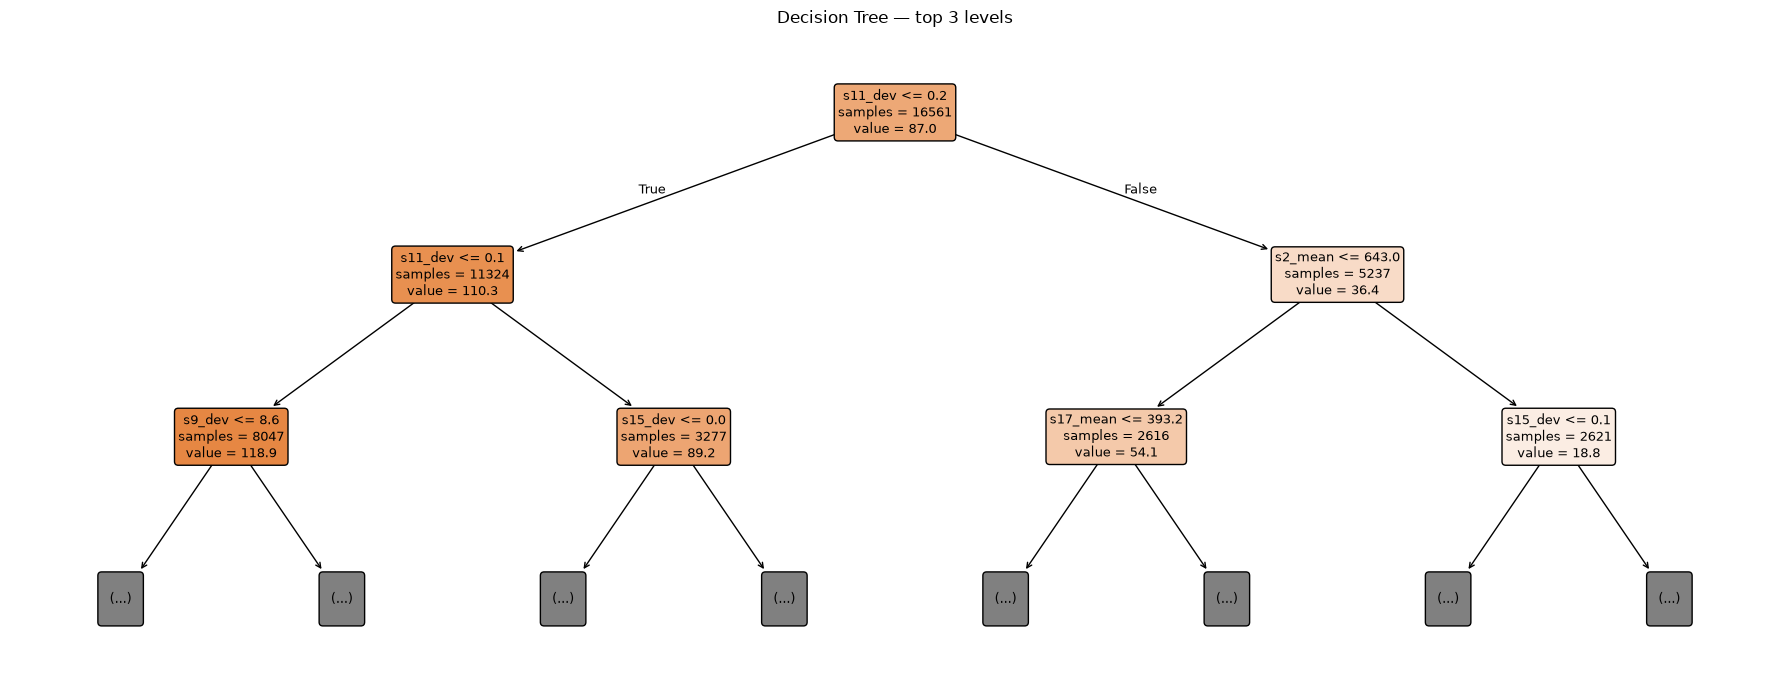

In [7]:
plt.figure(figsize=(18, 7))
plot_tree(model, max_depth=2, feature_names=FEATURES, filled=True, rounded=True, fontsize=9, impurity=False, precision=1)
plt.title("Decision Tree — top 3 levels")
savefig("04_tree_diagram")

### Overfitting and pruning
A tree that grows **too deep** memorises the training engines (training error → 0) but does badly on new engines.
Below: training vs validation error for different `max_depth` values.

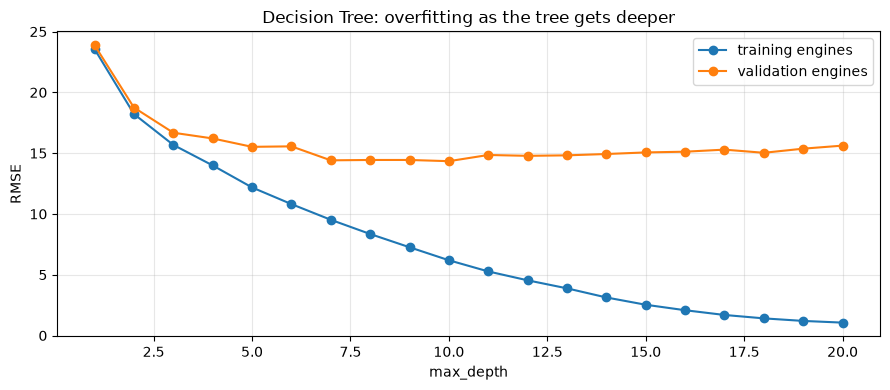

In [8]:
depths = range(1, 21)
train_err, val_err = [], []
for d in depths:
    t = DecisionTreeRegressor(max_depth=d, random_state=SEED).fit(X_train, y_train)
    train_err.append(evaluate(y_train, t.predict(X_train))["RMSE"])
    val_err.append(evaluate(y_val, t.predict(X_val))["RMSE"])
plt.figure(figsize=(9, 4))
plt.plot(depths, train_err, "o-", label="training engines")
plt.plot(depths, val_err, "o-", label="validation engines")
plt.title("Decision Tree: overfitting as the tree gets deeper"); plt.xlabel("max_depth"); plt.ylabel("RMSE")
plt.legend()
savefig("04_overfitting_depth")

**Observation:** training error keeps falling as the tree gets deeper, but validation error stops improving and then
gets worse → **overfitting**. That is why we **prune** the tree (limit `max_depth`, `min_samples_leaf`, `ccp_alpha`).

## 5. Do the engineered features help?
Same model, same settings, but trained with **only the raw sensors + cycle** (15 features instead of 71).

In [9]:
RAW = [f for f in FEATURES if "_" not in f]   # cycle + 14 raw sensors
raw_model = clone(model).fit(X_train[RAW], y_train)   # clone = untrained copy with the same settings
raw_rmse = evaluate(y_val, np.clip(raw_model.predict(val[RAW]), 0, RUL_CAP))["RMSE"]
eng_rmse = evaluate(y_val, val_pred)["RMSE"]

pd.DataFrame({"Validation RMSE": [raw_rmse, eng_rmse]},
             index=["Raw sensors only (15 features)", "With engineered features (71)"])

,Validation RMSE
Raw sensors only (15 features),17.73
With engineered features (71),14.13


## 6. Early vs late life
* **Early:** true RUL > 100 (engine still healthy)
* **Late:** true RUL ≤ 100 (engine is wearing out — the important part for maintenance)

In [10]:
stage_table(val["RUL_raw"], y_val, val_pred)

,Rows,RMSE,MAE
Stage,,,
early (RUL > 100),2050,10.01,5.65
late (RUL ≤ 100),2020,17.33,12.75


## 7. Official NASA test set (100 engines)
* Re-train the model with the same settings on **all 100 training engines**.
* Predict each test engine **once, at its last recorded cycle**, and compare with the true RUL from `RUL_FD001.txt`.
* Nothing is tuned on the test set.

In [11]:
final_model = clone(model).fit(train[FEATURES], train["RUL"])   # same settings, trained on all 100 engines
test_pred = np.clip(final_model.predict(test[FEATURES]), 0, RUL_CAP)
pd.DataFrame([evaluate(test["RUL"], test_pred)], index=[NAME + " (test)"])

,RMSE,MAE,R2
Decision Tree (test),14.96,10.8,0.861


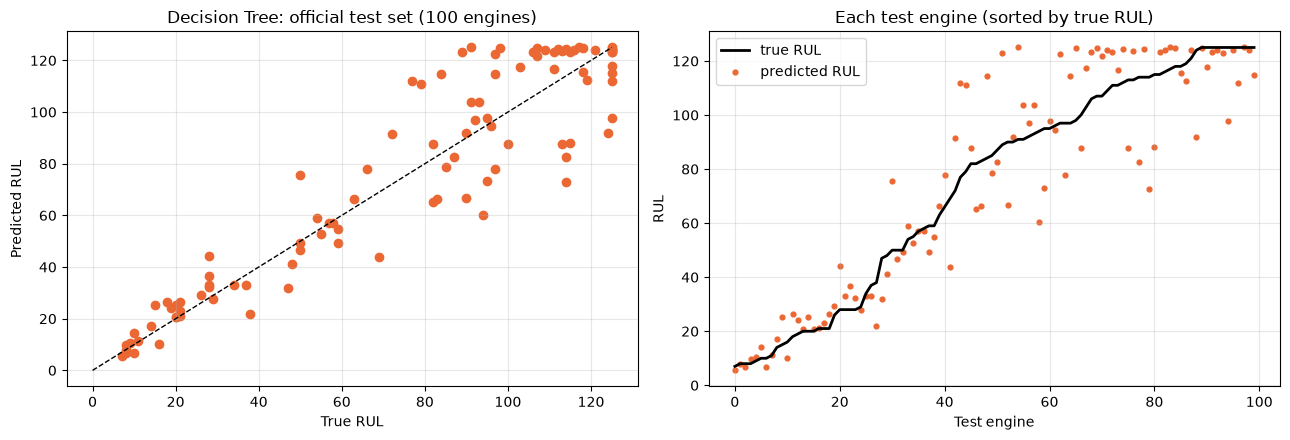

In [12]:
plot_test(NAME, test["RUL"], test_pred, "04_test")

## 8. Save the model and predictions (used by notebook 06 and the web app)

In [13]:
joblib.dump(final_model, "../outputs/models/decision_tree.joblib")

# Save predictions so notebook 06 can compare all models without training them again
val[["unit", "cycle", "RUL_raw", "RUL"]].assign(predicted=val_pred).to_csv(
    "../outputs/results/decision_tree_val_predictions.csv", index=False)
test[["unit", "RUL_raw", "RUL"]].assign(predicted=test_pred).to_csv(
    "../outputs/results/decision_tree_test_predictions.csv", index=False)
pd.DataFrame([{"Model": NAME, "raw_sensors_only_val_RMSE": raw_rmse}]).to_csv(
    "../outputs/results/decision_tree_raw_vs_engineered.csv", index=False)
print("Saved model and predictions")

Saved model and predictions


## ✅ Summary — Decision Tree
* Clearly better than the linear models, because it learns the **non-linear** degradation pattern.
* Easy to explain (you can follow the questions in the diagram), but a single tree is **unstable**:
  small changes in the data can change the whole tree → **high variance**. Random Forest fixes this → notebook 05.

**Viva quick answers**
* *Gini / Entropy in a regression tree?* Those are for classification. A regression tree uses **MSE reduction** to choose splits.
* *How did you handle overfitting?* Pruning: limited `max_depth` / `min_samples_leaf` (pre-pruning) and `ccp_alpha` (post-pruning), chosen by cross-validation.